# Kryptonite-20: RBF SVM cross-validation

This notebook reproduces a figure from the saved training-only 3-fold cross-validation results in `results/cv20/cv_summary.csv`. The full cross-validation training is implemented separately in `svm_cv.py`. Run this notebook with the project Python environment, with the working directory set to `B_Traditional_ML/`. The generated files are `results/cv20/figures/rbf_cv_accuracy.png` and `results/cv20/figures/rbf_cv_accuracy.pdf`.

Each cell in the figure shows mean accuracy across three folds. The folds are partitions of the shared training split. The prior validation results informed the parameter grid, and these CV results were used for model selection; the figure describes the development experiment. The shared local test and hidden sets remain held out. Fold-level results and variability are available in `results/cv20/`.


In [1]:
from pathlib import Path
import csv
import hashlib
import json

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

source = Path("results/cv20/cv_summary.csv")
manifest_path = Path("results/cv20/run_manifest.json")
if not source.is_file() or not manifest_path.is_file():
    raise FileNotFoundError("Run this notebook with B_Traditional_ML as the working directory, after completing the CV experiment.")

source_hash = hashlib.sha256(source.read_bytes()).hexdigest()
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
with source.open(encoding="utf-8", newline="") as stream:
    rows = [row for row in csv.DictReader(stream) if row["kernel"] == "rbf"]

c_values = sorted({float(row["C"]) for row in rows})
gamma_values = sorted({float(row["gamma"]) for row in rows})
lookup = {(float(row["C"]), float(row["gamma"])): float(row["mean_accuracy"]) for row in rows}
if len(rows) != 12 or len(lookup) != 12 or c_values != [1.0, 10.0, 100.0] or gamma_values != [0.05, 0.1, 0.2, 0.4]:
    raise ValueError("Expected exactly the 12 planned RBF configurations.")
accuracy = np.array([[lookup[(c, gamma)] for gamma in gamma_values] for c in c_values])
if not np.isfinite(accuracy).all() or np.any((accuracy < 0) | (accuracy > 1)):
    raise ValueError("Accuracy values must be finite numbers between 0 and 1.")

print("Source:", source)
print("CSV SHA-256:", source_hash)
print("Training/CV samples:", manifest["identity"]["training_samples"])
print("CV split seed:", manifest["identity"]["cv_seed"])
print("CV folds:", manifest["identity"]["n_splits"])
print("Figure labels show mean CV accuracy (%).")

Source: results\cv20\cv_summary.csv
CSV SHA-256: 98703b49c393cfbf23af604273f7a1cc8c6bc94c3e12c695f86520579c473fa9
Training/CV samples: 8400
CV split seed: 67
CV folds: 3
Figure labels show mean CV accuracy (%).


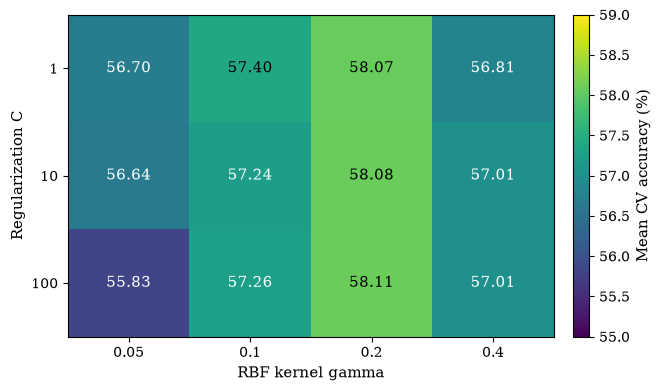

Saved: results\cv20\figures\rbf_cv_accuracy.png and results\cv20\figures\rbf_cv_accuracy.pdf


In [2]:
# Use the PDF core Type 1 fonts and retain readable labels at full figure width.
mpl.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.use14corefonts": True,
})

values = accuracy * 100.0
vmin, vmax = np.floor(values.min()), np.ceil(values.max())
if vmin == vmax:
    vmin, vmax = vmin - 0.5, vmax + 0.5

fig, ax = plt.subplots(figsize=(6.5, 3.8), layout="constrained")
heatmap = ax.imshow(values, cmap="viridis", aspect="auto", vmin=vmin, vmax=vmax)
ax.set_xticks(range(len(gamma_values)), [f"{value:g}" for value in gamma_values])
ax.set_yticks(range(len(c_values)), [f"{value:g}" for value in c_values])
ax.set_xlabel("RBF kernel gamma")
ax.set_ylabel("Regularization C")

for i in range(len(c_values)):
    for j in range(len(gamma_values)):
        rgba = heatmap.cmap(heatmap.norm(values[i, j]))
        luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                color="black" if luminance > 0.53 else "white", fontsize=11)

colorbar = fig.colorbar(heatmap, ax=ax, pad=0.04)
colorbar.set_label("Mean CV accuracy (%)")

figure_dir = Path("results/cv20/figures")
figure_dir.mkdir(parents=True, exist_ok=True)
png_path = figure_dir / "rbf_cv_accuracy.png"
pdf_path = figure_dir / "rbf_cv_accuracy.pdf"
fig.savefig(png_path, dpi=220, bbox_inches="tight")
# Times-Roman is a PDF core Type 1 font whose AFM weight is named "roman".
for item in fig.findobj(match=mpl.text.Text):
    item.set_weight("roman")
fig.savefig(pdf_path, bbox_inches="tight")
for item in fig.findobj(match=mpl.text.Text):
    item.set_weight("normal")
display(fig)
plt.close(fig)
print("Saved:", png_path, "and", pdf_path)

Suggested caption: **Mean validation accuracy within training-set 3-fold cross-validation for 12 RBF SVM configurations on Kryptonite-20.** Each fold used a scaler fitted on that fold's training data. Values are percentages; fold-level results are retained in the accompanying CSV and JSON records.

The PDF is intended for placement at its approximately 6.5-inch full width; reduce its size only after checking that the resulting labels remain at least as large as the report body text. The caption belongs below the figure in the report.